In [1]:
EXPERIMENT = {
    "start": "2025-02-01",
    "end":   "2025-09-30",
    "interval": "5m",
    "universe_rule": "full_coverage_only",
}


In [2]:
# Import the class from the Python file (module)
import pandas as pd
import matplotlib.pyplot as plt
import os
# from dotenv import load_dotenv
# from pathlib import Path
from sklearn.preprocessing import StandardScaler
import seaborn as sns
from BinanceClient import BinanceClient
import numpy as np
from typing import Final
import joblib
from BatchFeatures import BatchFeatures
from datetime import datetime, timedelta
import helper_functions as hf
import importlib
%matplotlib widget

## Load pair df & Truncate data to 40 Weeks

In [3]:
START_TS = "2025-02-01 00:00:00"
END_TS   = "2025-09-30 23:55:00"   # align to 5m bar end

paths = {}
dfs = {}
interval = "5m"

pairs = hf.list_downloaded_pairs("db")

for sym in pairs:
    db_path, df = hf.load_or_fetch_pair_df(sym, interval, weeks=52)

    df = hf.filter_date_range(
        df,
        START_TS,
        END_TS,
        require_full_coverage=True,
        min_coverage_ratio=1.0,      # strict: must cover entire window
        return_none_if_short=True
    )

    if df is None:
        continue

    paths[sym] = db_path
    dfs[sym] = df

print("kept syms:", len(dfs), "out of", len(pairs))

[0GUSDT] DB: ./db/0GUSDT_5m_52weeks.db
[0GUSDT] Loaded 36,249 rows from DB.
[1INCHUSDT] DB: ./db/1INCHUSDT_5m_52weeks.db
[1INCHUSDT] Loaded 104,832 rows from DB.
[2ZUSDT] DB: ./db/2ZUSDT_5m_52weeks.db
[2ZUSDT] Loaded 33,383 rows from DB.
[AAVEUSDT] DB: ./db/AAVEUSDT_5m_52weeks.db
[AAVEUSDT] Loaded 104,832 rows from DB.
[ADAUSDT] DB: ./db/ADAUSDT_5m_52weeks.db
[ADAUSDT] Loaded 104,832 rows from DB.
[AGLDUSDT] DB: ./db/AGLDUSDT_5m_52weeks.db
[AGLDUSDT] Loaded 104,832 rows from DB.
[ALGOUSDT] DB: ./db/ALGOUSDT_5m_52weeks.db
[ALGOUSDT] Loaded 104,832 rows from DB.
[ALLOUSDT] DB: ./db/ALLOUSDT_5m_52weeks.db
[ALLOUSDT] Loaded 21,807 rows from DB.
[APTUSDT] DB: ./db/APTUSDT_5m_52weeks.db
[APTUSDT] Loaded 104,832 rows from DB.
[ARBUSDT] DB: ./db/ARBUSDT_5m_52weeks.db
[ARBUSDT] Loaded 104,832 rows from DB.
[ASTERUSDT] DB: ./db/ASTERUSDT_5m_52weeks.db
[ASTERUSDT] Loaded 32,185 rows from DB.
[ASTRUSDT] DB: ./db/ASTRUSDT_5m_52weeks.db
[ASTRUSDT] Loaded 104,832 rows from DB.
[AUCTIONUSDT] DB: ./db/

## Load COINS, then align timestamps

In [4]:
from tqdm.auto import tqdm
events = []

# for sym, df_feat in tqdm(instability_cache.items(), desc="Cond prob (fast)"):
for sym, df in tqdm(dfs.items()):
    ev = hf.detect_volume_shocks(df)      # ✅ no sym passed
    if not ev.empty:
        ev["symbol"] = sym
        events.append(ev)

events = pd.concat(events, ignore_index=True) if events else pd.DataFrame()


  0%|          | 0/83 [00:00<?, ?it/s]

## Detect Comporession state

In [5]:
# Build dataset
ds = hf.build_preshock_dataset(
    dfs=dfs,
    events=events,
    pre_bars=36,
    gap_bars=2,
    control_per_event=1,
    control_lookahead_bars=36,
    seed=42
)

ds.shape, ds["label"].value_counts()

((10848, 12),
 label
 1    5424
 0    5424
 Name: count, dtype: int64)

In [6]:
# sym = "BTCUSDT"
df_feat = hf.compute_instability_features_over_window(dfs[sym])
df_feat["is_instability"] = hf.classify_instability(df_feat)

# df_feat["is_instability"].mean(), df_feat["is_instability"].tail(50)


In [7]:
features = ["rvol_mean","rvol_slope","atr_mean_ratio","wick_to_body_ratio","range_pct"]
best_list = [hf.best_threshold_youden(ds, f, higher_is_more_shock=True) for f in features]
pd.DataFrame(best_list).sort_values("J", ascending=False)


,feature,thr,TPR,FPR,J
4,range_pct,0.036171,0.799041,0.220870,0.578171
1,rvol_slope,0.028844,0.600479,0.219580,0.380900
0,rvol_mean,1.853116,0.610435,0.309550,0.300885
2,atr_mean_ratio,1.137608,0.531158,0.268805,0.262353
3,wick_to_body_ratio,1.348668,0.724926,0.535029,0.189897


In [8]:

df_feat = hf.compute_instability_features_over_window(dfs[sym])
df_feat["is_instability"] = hf.classify_pre_shock_instability_v1(df_feat)

ev = events.query("symbol == @sym")
df_feat = hf.mark_future_shock(df_feat, ev, horizon_bars=24)  # 120 min

p_base = df_feat["future_shock"].mean()
p_cond = df_feat.loc[df_feat["is_instability"], "future_shock"].mean()

p_base, p_cond, p_cond / p_base


(np.float64(0.029155188246097336),
 np.float64(0.11749271137026239),
 np.float64(4.029907486054039))

In [9]:
events_by_sym = {s: g["event_ts"].values for s, g in events.groupby("symbol")}

In [10]:
from tqdm.auto import tqdm
import time

# ============================================================
# FIX #1: Cache instability once per symbol (WITH PROGRESS)
# ============================================================
instability_cache = {}

t0 = time.time()

for sym in tqdm(pairs, desc="Computing instability per symbol"):
    if sym not in dfs:
        continue

    df = dfs[sym]
    if df is None or df.empty:
        continue
    
    df_feat = hf.compute_instability_features_over_window(df)
    is_inst = hf.classify_pre_shock_instability_v1(df_feat)
    instability_cache[sym] = pd.DataFrame({"is_instability": is_inst}, index=df_feat.index)

t1 = time.time()
print(f"Instability cache built in {(t1 - t0)/60:.2f} minutes")


Computing instability per symbol:   0%|          | 0/119 [00:00<?, ?it/s]

Instability cache built in 5.51 minutes


In [11]:
# Choose how many cores to use
N_WORKERS = 4  # you said 10–12 is fine
instability_cache = hf.build_instability_cache_parallel(dfs, pairs, n_workers=N_WORKERS)


Instability x4:   0%|          | 0/83 [00:00<?, ?it/s]

Instability cache built for 83/83 symbols in 1.52 min


In [12]:
rows = []
horizon_bars = 24  # 120 min

for sym, df_feat in tqdm(instability_cache.items(), desc="Cond prob (fast)"):
    ev_ts = events_by_sym.get(sym)
    if ev_ts is None or len(ev_ts) == 0:
        continue

    idx = df_feat.index
    is_inst = df_feat["is_instability"].to_numpy(dtype=bool)
    n_inst = int(is_inst.sum())
    if n_inst < 10:
        continue

    fut = hf.future_shock_flag(idx, ev_ts, horizon_bars=horizon_bars)

    p_base = float(fut.mean())
    p_cond = float(fut[is_inst].mean())

    rows.append({
        "symbol": sym,
        "base_prob": p_base,
        "cond_prob": p_cond,
        "lift": (p_cond / p_base) if p_base > 0 else np.nan,
        "instability_rate": float(is_inst.mean()),
        "n_instability": n_inst,
        "n_shocks": int(len(ev_ts)),
    })

prob_df = pd.DataFrame(rows).sort_values("lift", ascending=False)
prob_df.head(20)

Cond prob (fast):   0%|          | 0/83 [00:00<?, ?it/s]

,symbol,base_prob,cond_prob,lift,instability_rate,n_instability,n_shocks
32,FDUSDUSDT,0.000531,0.500000,941.837838,0.000316,22,2
16,BNBUSDT,0.001722,0.056604,32.875472,0.011407,795,5
63,SUNUSDT,0.010833,0.251656,23.230981,0.012999,906,36
18,BTCUSDT,0.002253,0.048426,21.497509,0.005926,413,7
38,JSTUSDT,0.003888,0.051546,13.256743,0.011134,776,12
60,STGUSDT,0.006399,0.079122,12.364374,0.021579,1504,21
29,ETCUSDT,0.009814,0.093363,9.513232,0.025511,1778,31
22,DASHUSDT,0.008480,0.080654,9.511471,0.025439,1773,26
71,WBTCUSDT,0.002066,0.016355,7.915888,0.006141,428,6
66,TONUSDT,0.013229,0.098639,7.456373,0.025310,1764,42


# Pre shock feature extraction

## Compute event features

In [13]:
BAR_MINUTES = 5

PRE_HOURS = 12
BASE_HOURS = 72

PRE_BARS  = PRE_HOURS  * 60 // BAR_MINUTES   # 144
BASE_BARS = BASE_HOURS * 60 // BAR_MINUTES   # 864


In [15]:
import numpy as np
import pandas as pd

rows = []

for _, ev in events.iterrows():
    sym = ev["symbol"]
    ts  = ev["event_ts"]

    df = dfs.get(sym)
    if df is None:
        continue

    feats = hf.extract_pre_shock_features(df, ts)
    if feats is None:
        continue

    feats["symbol"]   = sym
    feats["event_ts"] = ts

    rows.append(feats)

event_features_df = pd.DataFrame(rows)
event_features_df.set_index(["symbol", "event_ts"], inplace=True)


In [16]:
for col in ["vol_ratio", "atr_ratio", "entropy", "volume_ratio"]:
    event_features_df[f"z_{col}"] = (
        event_features_df[col] - event_features_df[col].mean()
    ) / event_features_df[col].std()

event_features_df["compression_score"] = (
    event_features_df[["z_vol_ratio", "z_atr_ratio",
                       "z_entropy", "z_volume_ratio"]]
    .sum(axis=1)
)


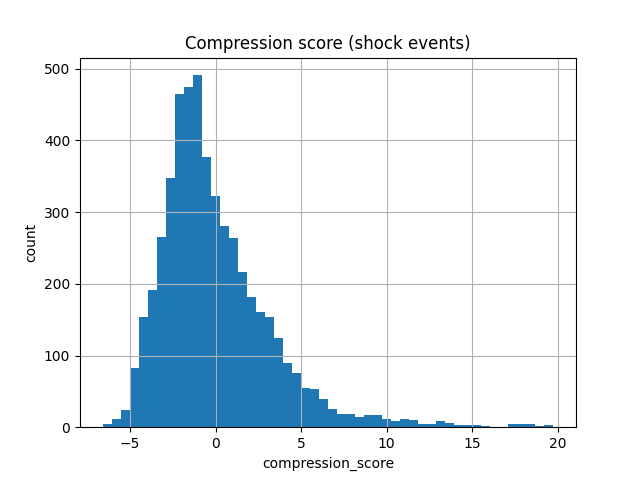

In [17]:
import matplotlib.pyplot as plt

ax = event_features_df["compression_score"].hist(bins=50)
ax.set_title("Compression score (shock events)")
ax.set_xlabel("compression_score")
ax.set_ylabel("count")
plt.show()


## Non-Shock histogramming

In [18]:
rng = np.random.default_rng(42)

In [19]:
non_events = hf.sample_non_event_timestamps(dfs, events, rng)
len(non_events), non_events.head()


(5424,
       symbol            event_ts
 0  1INCHUSDT 2025-05-04 00:00:00
 1  1INCHUSDT 2025-03-29 01:45:00
 2  1INCHUSDT 2025-08-05 13:05:00
 3  1INCHUSDT 2025-02-24 01:00:00
 4  1INCHUSDT 2025-09-24 22:35:00)

In [20]:
rows = []
for _, row in non_events.iterrows():
    sym = row["symbol"]
    ts  = row["event_ts"]
    df = dfs[sym]

    feats = hf.extract_pre_shock_features(df, ts)
    if feats is None:
        continue

    feats["symbol"] = sym
    feats["event_ts"] = ts
    rows.append(feats)

non_event_features_df = pd.DataFrame(rows).set_index(["symbol", "event_ts"])
non_event_features_df.describe()


,vol_ratio,atr_ratio,entropy,volume_ratio,failed_breakouts
count,5424.000000,5424.000000,5424.000000,5424.000000,5424.000000
mean,0.955457,0.984106,0.079816,0.982878,5.104904
std,0.255817,0.275176,0.058611,0.482019,2.396495
min,0.226729,0.282119,0.000000,0.146970,0.000000
25%,0.778591,0.803608,0.033939,0.648321,3.000000
50%,0.939233,0.959563,0.069228,0.894099,5.000000
75%,1.106037,1.126646,0.113861,1.212985,6.000000
max,2.294402,4.701093,0.404051,5.106917,18.000000


In [21]:
z_cols = ["vol_ratio", "atr_ratio", "entropy", "volume_ratio"]

mu = event_features_df[z_cols].mean()
sd = event_features_df[z_cols].std()

for col in z_cols:
    non_event_features_df[f"z_{col}"] = (non_event_features_df[col] - mu[col]) / sd[col]

non_event_features_df["compression_score"] = non_event_features_df[
    ["z_vol_ratio", "z_atr_ratio", "z_entropy", "z_volume_ratio"]
].sum(axis=1)


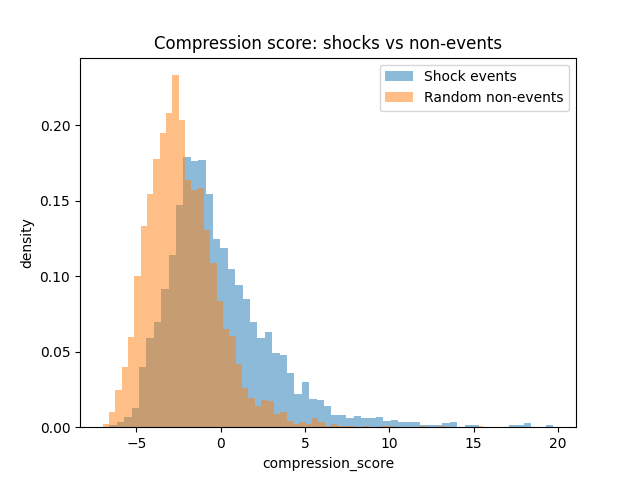

In [22]:
plt.figure()
plt.hist(event_features_df["compression_score"], bins=60, alpha=0.5, density=True, label="Shock events")
plt.hist(non_event_features_df["compression_score"], bins=60, alpha=0.5, density=True, label="Random non-events")
plt.legend()
plt.title("Compression score: shocks vs non-events")
plt.xlabel("compression_score")
plt.ylabel("density")
plt.show()


## Compression Filter

In [23]:
COMPRESSION_THRESH = -2.6
RANGE_BARS = 24   # last 2 hours

eligible_events = event_features_df[
    event_features_df["compression_score"] < COMPRESSION_THRESH
]
len(eligible_events), len(eligible_events) / len(event_features_df)


(923, 0.18055555555555555)

In [24]:
entries = []

for (sym, ts), row in eligible_events.iterrows():
    df = dfs[sym]
    res = hf.find_pre_shock_entry(df, ts)
    if res is None:
        continue

    res["symbol"] = sym
    res["event_ts"] = ts
    res["compression_score"] = row["compression_score"]
    entries.append(res)

entries_df = pd.DataFrame(entries)
entries_df = entries_df.merge(
    events[["symbol","event_ts","shock_direction","impulse_signed","impulse"]],
    on=["symbol","event_ts"],
    how="left"
)

entries_df.head()


,entry_ts,direction,entry_price,symbol,event_ts,compression_score,shock_direction,impulse_signed,impulse
0,2025-02-04 02:35:00,long,0.2678,1INCHUSDT,2025-02-04 05:10:00,-4.104449,short,-0.043381,0.043381
1,2025-04-09 14:55:00,short,0.1582,1INCHUSDT,2025-04-09 17:20:00,-2.833294,long,0.043723,0.043723
2,2025-03-05 22:55:00,short,217.3500,AAVEUSDT,2025-03-06 01:45:00,-2.925978,long,0.052803,0.052803
3,2025-03-06 22:40:00,long,212.7200,AAVEUSDT,2025-03-07 01:40:00,-2.796143,long,0.044892,0.044892
4,2025-03-14 12:30:00,short,166.7000,AAVEUSDT,2025-03-14 15:15:00,-2.807180,long,0.040847,0.040847


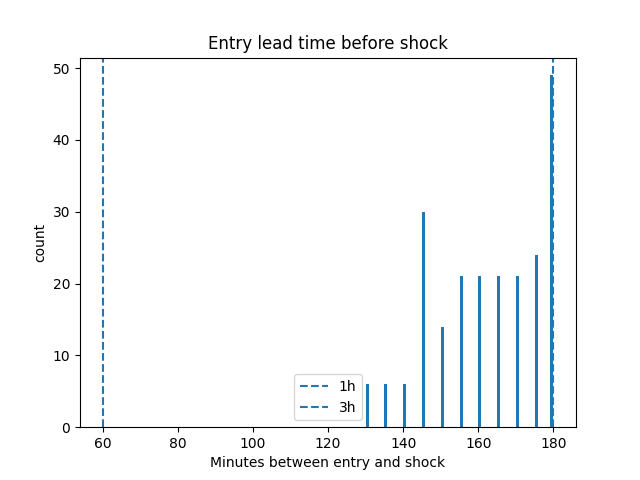

In [25]:
dt_minutes = (
    entries_df["event_ts"] - entries_df["entry_ts"]
).dt.total_seconds() / 60

plt.figure()
plt.hist(dt_minutes, bins=60)
plt.axvline(60, linestyle="--", label="1h")
plt.axvline(180, linestyle="--", label="3h")
plt.xlabel("Minutes between entry and shock")
plt.ylabel("count")
plt.title("Entry lead time before shock")
plt.legend()
plt.show()


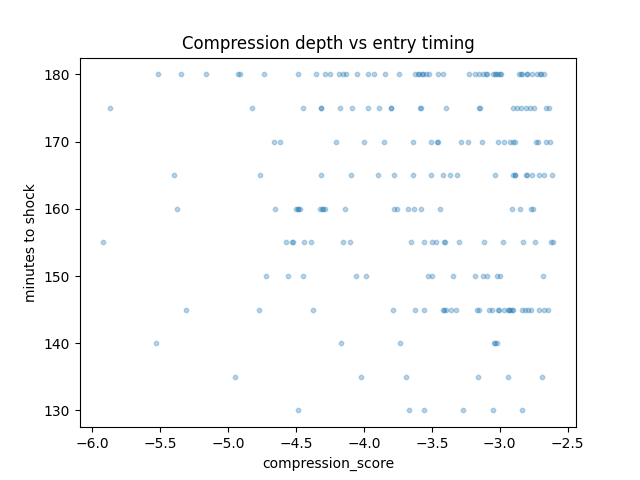

In [26]:
plt.figure()
plt.scatter(
    entries_df["compression_score"],
    dt_minutes,
    alpha=0.3,
    s=10
)
plt.xlabel("compression_score")
plt.ylabel("minutes to shock")
plt.title("Compression depth vs entry timing")
plt.show()


In [27]:
entries_df["direction"].value_counts(normalize=True)


direction
short    0.557078
long     0.442922
Name: proportion, dtype: float64

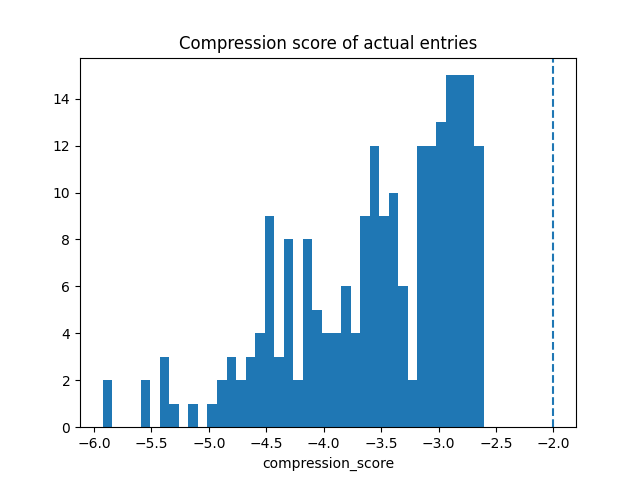

In [28]:
plt.figure()
plt.hist(entries_df["compression_score"], bins=40)
plt.axvline(-2.0, linestyle="--")
plt.xlabel("compression_score")
plt.title("Compression score of actual entries")
plt.show()


## Direction alignment filtering

In [29]:
entries_df["shock_direction"] = entries_df.apply(
    hf.compute_shock_direction,
    axis=1,
    args=(dfs,)
)

entries_df["shock_direction"].value_counts()


shock_direction
long     140
short     79
Name: count, dtype: int64

In [30]:
aligned_entries = entries_df[
    entries_df["direction"] == entries_df["shock_direction"]
]
aligned_entries["direction"].value_counts(normalize=True)


direction
long     0.736842
short    0.263158
Name: proportion, dtype: float64

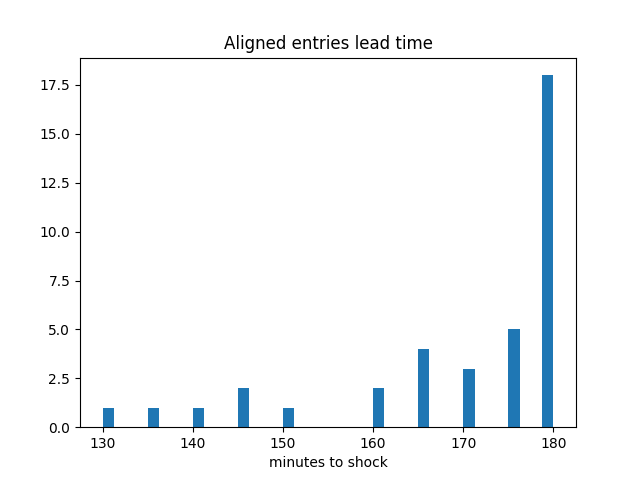

In [31]:
dt_aligned = (
    aligned_entries["event_ts"] - aligned_entries["entry_ts"]
).dt.total_seconds() / 60

plt.figure()
plt.hist(dt_aligned, bins=40)
plt.xlabel("minutes to shock")
plt.title("Aligned entries lead time")
plt.show()


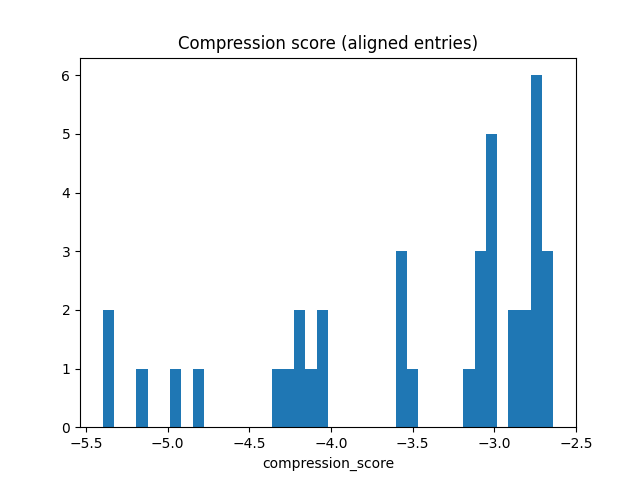

In [32]:
plt.figure()
plt.hist(aligned_entries["compression_score"], bins=40)
plt.xlabel("compression_score")
plt.title("Compression score (aligned entries)")
plt.show()


In [33]:
BAR_MINUTES = 5
FEE = 0.001  # 0.1% spot fee (round-trip will be 2x if you want later)

rows = []

for _, r in aligned_entries.iterrows():
    sym = r["symbol"]
    df  = dfs[sym]

    entry_ts = r["entry_ts"]
    event_ts = r["event_ts"]
    exit_ts  = event_ts + pd.Timedelta(minutes=BAR_MINUTES)

    # safety checks
    if entry_ts not in df.index:
        continue
    if exit_ts not in df.index:
        continue

    entry_px = df.loc[entry_ts, "close"]
    exit_px  = df.loc[exit_ts, "close"]

    if r["direction"] == "long":
        ret = (exit_px - entry_px) / entry_px
    else:  # short
        ret = (entry_px - exit_px) / entry_px

    ret_net = ret - 2*FEE

    rows.append({
        "symbol": sym,
        "direction": r["direction"],
        "entry_ts": entry_ts,
        "event_ts": event_ts,              # ✅ keep it
        "exit_ts": exit_ts,
        "entry_px": entry_px,
        "exit_px": exit_px,
        "ret": ret,
        "ret_net": ret_net,
        "compression_score": r["compression_score"],
    })


trades = pd.DataFrame(rows)
len(trades)


38

In [34]:
hf.summarize(trades)


{'trades': 38,
 'win_rate': np.float64(0.6578947368421053),
 'avg_ret': np.float64(0.008160338992195877),
 'median_ret': 0.0016350850408603532,
 'total_ret': np.float64(0.31009288170344335),
 'avg_win': np.float64(0.017340130817212317),
 'avg_loss': np.float64(-0.00949310682514343)}

In [35]:
trades.groupby("direction").apply(
    lambda x: pd.Series({
        "trades": len(x),
        "win_rate": (x["ret_net"] > 0).mean(),
        "avg_ret": x["ret_net"].mean(),
    })
)


/tmp/ipykernel_2098/1868759965.py:1: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  trades.groupby("direction").apply(


,trades,win_rate,avg_ret
direction,,,
long,28.0,0.678571,0.005739
short,10.0,0.600000,0.014941


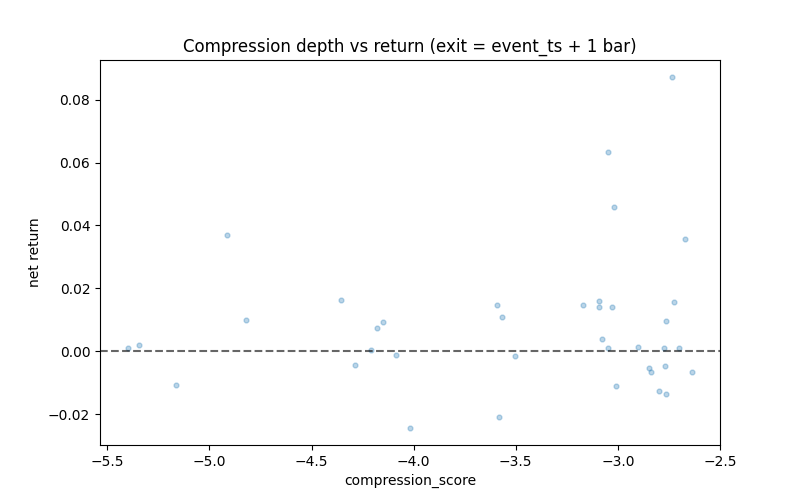

In [36]:
plt.figure(figsize=(8,5))
plt.scatter(
    trades["compression_score"],
    trades["ret_net"],
    alpha=0.3,
    s=12
)
plt.axhline(0, linestyle="--", color="k", alpha=0.6)
plt.xlabel("compression_score")
plt.ylabel("net return")
plt.title("Compression depth vs return (exit = event_ts + 1 bar)")
plt.show()


In [37]:
trades["comp_bucket"] = pd.qcut(
    trades["compression_score"],
    q=4,
    labels=["Q1 (deep)","Q2","Q3","Q4 (shallow)"]
)

bucket_stats = trades.groupby("comp_bucket")["ret_net"].agg(
    count="count",
    mean="mean",
    median="median",
    win_rate=lambda s: (s > 0).mean()
)

bucket_stats


/tmp/ipykernel_2098/2940587472.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  bucket_stats = trades.groupby("comp_bucket")["ret_net"].agg(


,count,mean,median,win_rate
comp_bucket,,,,
Q1 (deep),10,0.006847,0.004736,0.800000
Q2,9,0.002490,0.010712,0.555556
Q3,9,0.011876,0.001257,0.666667
Q4 (shallow),10,0.011234,0.000936,0.600000


# From this point onwards, we only consider long trades

In [38]:
long_trades = trades[trades["direction"] == "long"].copy()

long_trades["comp_bucket"] = pd.qcut(
    long_trades["compression_score"],
    q=4,
    labels=["Q1 (deep)","Q2","Q3","Q4 (shallow)"]
)
long_trades["comp_bucket"] = long_trades["comp_bucket"].astype("string")

long_bucket_stats = long_trades.groupby("comp_bucket")["ret_net"].agg(
    count="count",
    mean="mean",
    median="median",
    win_rate=lambda s: (s > 0).mean()
)


long_bucket_stats


,count,mean,median,win_rate
comp_bucket,,,,
Q1 (deep),7,0.007298,0.002013,0.714286
Q2,7,0.000689,0.009412,0.714286
Q3,7,0.003486,0.001257,0.714286
Q4 (shallow),7,0.011482,0.000876,0.571429


In [39]:
long_trades = trades[trades["direction"] == "long"].copy()
len(long_trades), long_trades["symbol"].nunique()


(28, 22)

In [40]:
H1 = 24   # 2h
H2 = 72   # 6h
BAR_MIN = 5

In [41]:

rows = []
for _, r in long_trades.iterrows():
    sym = r["symbol"]
    res1 = hf.post_shock_stats_for_trade(sym, r["entry_ts"], r["event_ts"], r["direction"], dfs, H1)
    res2 = hf.post_shock_stats_for_trade(sym, r["entry_ts"], r["event_ts"], r["direction"], dfs, H2)
    if res1 is None or res2 is None:
        continue
    mfe1, mae1, ttp1, ret1 = res1
    mfe2, mae2, ttp2, ret2 = res2

    rows.append({
        "symbol": sym,
        "entry_ts": r["entry_ts"],
        "event_ts": r["event_ts"],
        "compression_score": r["compression_score"],
        "mfe_2h": mfe1, "mae_2h": mae1, "ttp_2h": ttp1, "ret_2h": ret1,
        "mfe_6h": mfe2, "mae_6h": mae2, "ttp_6h": ttp2, "ret_6h": ret2,
        "ret_net_v1": r["ret_net"],  # your current time-exit result
    })

post = pd.DataFrame(rows)
post.describe()


,entry_ts,event_ts,compression_score,mfe_2h,mae_2h,ttp_2h,ret_2h,mfe_6h,mae_6h,ttp_6h,ret_6h,ret_net_v1
count,28,28,28.000000,28.000000,28.000000,28.000000,28.000000,28.000000,28.000000,28.000000,28.000000,28.000000
mean,2025-04-11 00:33:23.571428096,2025-04-11 03:25:53.571428352,-3.593014,0.023321,-0.017029,9.750000,-0.001409,0.061472,-0.021627,46.964286,0.038657,0.005739
min,2025-02-04 20:10:00,2025-02-04 23:10:00,-5.398325,-0.010530,-0.074136,0.000000,-0.063184,-0.010060,-0.074136,0.000000,-0.050489,-0.024277
25%,2025-03-04 11:35:00,2025-03-04 14:35:00,-4.228581,0.012923,-0.028386,1.000000,-0.021170,0.031620,-0.038125,34.500000,0.012343,-0.005592
50%,2025-03-04 13:05:00,2025-03-04 16:05:00,-3.130830,0.017500,-0.015666,11.000000,0.007421,0.044987,-0.017560,58.000000,0.029885,0.001635
75%,2025-05-20 12:00:00,2025-05-20 14:51:15,-2.828286,0.032151,-0.003259,15.750000,0.015586,0.090142,-0.004847,65.250000,0.048538,0.014270
max,2025-08-26 09:50:00,2025-08-26 12:35:00,-2.637385,0.116743,0.061332,24.000000,0.068241,0.166993,0.032076,72.000000,0.155213,0.087038
std,NaN,NaN,0.902938,0.022799,0.025076,9.012851,0.029725,0.046652,0.022999,25.038462,0.046012,0.020613


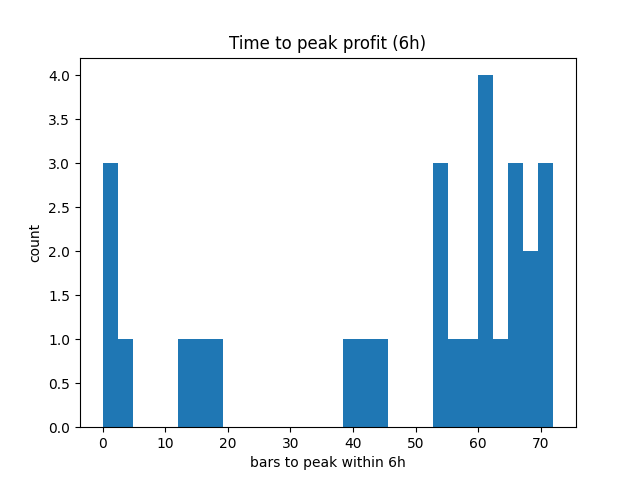

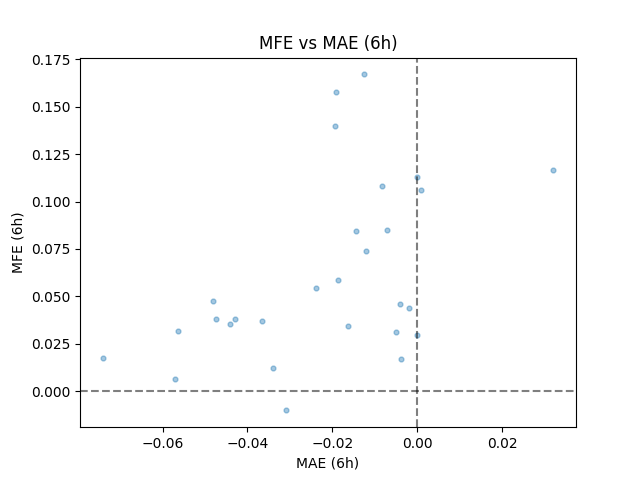

In [42]:
plt.figure()
plt.hist(post["ttp_6h"], bins=30)
plt.xlabel("bars to peak within 6h")
plt.ylabel("count")
plt.title("Time to peak profit (6h)")
plt.show()

plt.figure()
plt.scatter(post["mae_6h"], post["mfe_6h"], alpha=0.4, s=12)
plt.axhline(0, linestyle="--", color="k", alpha=0.5)
plt.axvline(0, linestyle="--", color="k", alpha=0.5)
plt.xlabel("MAE (6h)")
plt.ylabel("MFE (6h)")
plt.title("MFE vs MAE (6h)")
plt.show()


## Simulate Long Exits

In [108]:
results = []

for _, r in long_trades.iterrows():
    sym = r["symbol"]
    df  = dfs[sym]

    out = hf.simulate_long_exit(
        df=df,
        entry_ts=r["entry_ts"],
        event_ts=r["event_ts"],
        entry_px=r["entry_px"],
        compression_score=r["compression_score"],
        H_MAX=72
    )
    if out is None:
        continue

    results.append({
        "symbol": sym,
        "entry_ts": r["entry_ts"],
        "event_ts": r["event_ts"],
        "entry_px": r["entry_px"],
        "compression_score": r["compression_score"],
        "comp_bucket": r.get("comp_bucket", np.nan),
        **out
    })

trades_v5 = pd.DataFrame(results)
trades_v5.shape


(28, 20)

In [109]:
hf.summarize(trades_v5)

trades_v5.groupby("exit_reason")["ret_net"].agg(
    count="count",
    mean="mean",
    median="median",
    win_rate=lambda s: (s > 0).mean()
).sort_values("count", ascending=False)


,count,mean,median,win_rate
exit_reason,,,,
TRAIL_GIVEBACK,17,0.006372,0.003164,0.705882
A_FAIL_NO_POP,8,-0.007806,-0.008195,0.125000
TIME_CAP,2,0.017421,0.017421,1.000000
SOFT_TIME_EXIT,1,-0.025824,-0.025824,0.000000


In [110]:
trades_v5.groupby("comp_bucket")["ret_net"].agg(
    count="count",
    mean="mean",
    median="median",
    win_rate=lambda s: (s > 0).mean()
)

,count,mean,median,win_rate
comp_bucket,,,,
Q1 (deep),9,0.002909,0.002846,0.666667
Q2,6,-0.003877,0.001238,0.500000
Q3,6,-0.005159,-0.006770,0.333333
Q4 (shallow),7,0.011848,0.004740,0.571429


In [111]:
base = trades[trades["direction"]=="long"].copy()

m = base.merge(
    trades_v5,
    on=["symbol","entry_ts","event_ts"],
    how="inner",
    suffixes=("_base", "_v5")
)

hf.summarize(m.rename(columns={"ret_net_base":"ret_net"}))
hf.summarize(m.rename(columns={"ret_net_v5":"ret_net"}))

(m["ret_net_v5"] - m["ret_net_base"]).describe()


count    28.000000
mean     -0.003778
std       0.013123
min      -0.027384
25%      -0.012586
50%      -0.002415
75%       0.004027
max       0.028090
dtype: float64

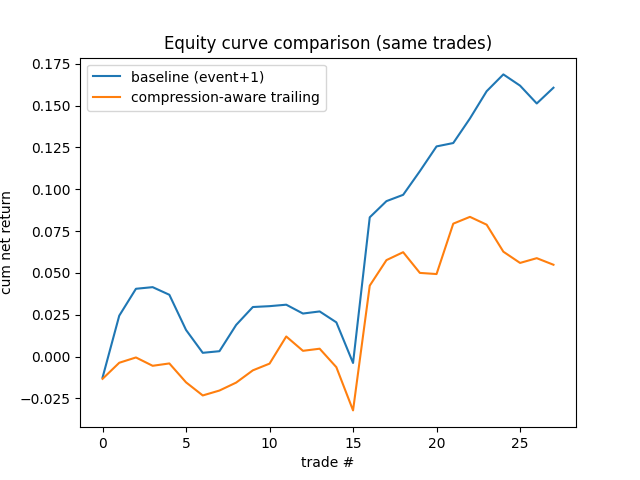

In [112]:
import matplotlib.pyplot as plt

plt.figure()
plt.plot(np.cumsum(m["ret_net_base"].values), label="baseline (event+1)")
plt.plot(np.cumsum(m["ret_net_v5"].values), label="compression-aware trailing")
plt.legend()
plt.title("Equity curve comparison (same trades)")
plt.xlabel("trade #")
plt.ylabel("cum net return")
plt.show()


In [113]:
trades_v5[["ret_net","mfe","mae"]].describe()
trades_v5["trail_active"].value_counts(dropna=False)
trades_v5["exit_reason"].value_counts(dropna=False)

# Any impossible cases?
(trades_v5["mfe"] < 0).sum(), (trades_v5["mae"] > 0).sum()


(np.int64(0), np.int64(7))

In [114]:
trades_v5_ref = trades_v5.copy()

## Baseline Comparison

In [115]:
trades_base = trades[trades["direction"]=="long"].copy()   # your baseline long trades
trades_v5_ref = trades_v5.copy()                           # fee-correct v5.1

cmp = hf.compare_vs_baseline(trades_base, trades_v5_ref, ret_col="ret_net")
summary = hf.summarize_cmp(cmp, ret_col="ret_net")

summary["overall"]
summary["by_bucket"]
summary["by_reason"]


,count,mean,median,win_rate
exit_reason,,,,
TRAIL_GIVEBACK,17,0.006372,0.003164,0.705882
A_FAIL_NO_POP,8,-0.007806,-0.008195,0.125000
TIME_CAP,2,0.017421,0.017421,1.000000
SOFT_TIME_EXIT,1,-0.025824,-0.025824,0.000000


In [116]:
print(trades_v5_ref["exit_reason"].value_counts())
print(hf.summarize_cmp(hf.compare_vs_baseline(trades_base, trades_v5_ref, ret_col="ret_net"))["overall"])
print(hf.summarize_cmp(hf.compare_vs_baseline(trades_base, trades_v5_ref, ret_col="ret_net"))["by_reason"])


exit_reason
TRAIL_GIVEBACK    17
A_FAIL_NO_POP      8
TIME_CAP           2
SOFT_TIME_EXIT     1
Name: count, dtype: int64
{'n': 28, 'mean_base': 0.005738673545850832, 'mean_v5': 0.0019607353104543392, 'mean_delta': -0.003777938235396494, 'median_delta': -0.0024148771822196974, 'winrate_base': 0.6785714285714286, 'winrate_v5': 0.5357142857142857, 'pct_improved': 0.35714285714285715}
                count      mean    median  win_rate
exit_reason                                        
TRAIL_GIVEBACK     17  0.006372  0.003164  0.705882
A_FAIL_NO_POP       8 -0.007806 -0.008195  0.125000
TIME_CAP            2  0.017421  0.017421  1.000000
SOFT_TIME_EXIT      1 -0.025824 -0.025824  0.000000


In [107]:
importlib.reload(hf)

<module 'helper_functions' from '/home/ata/binbot/helper_functions.py'>

In [117]:
coin_perf = (
    trades_v5_ref
    .groupby("symbol")
    .agg(
        n=("ret_net", "count"),
        mean_ret=("ret_net", "mean"),
        median_ret=("ret_net", "median"),
        win_rate=("ret_net", lambda x: (x > 0).mean()),
        total_ret=("ret_net", "sum"),
    )
    .sort_values("total_ret", ascending=False)
)

coin_perf


,n,mean_ret,median_ret,win_rate,total_ret
symbol,,,,,
PENGUUSDT,2,0.044901,0.044901,1.0,0.089802
TRUMPUSDT,2,0.017086,0.017086,1.0,0.034173
EIGENUSDT,2,0.010117,0.010117,1.0,0.020235
ADAUSDT,1,0.009614,0.009614,1.0,0.009614
DASHUSDT,1,0.007322,0.007322,1.0,0.007322
BONKUSDT,1,0.004740,0.004740,1.0,0.004740
PEPEUSDT,1,0.004731,0.004731,1.0,0.004731
AGLDUSDT,1,0.003164,0.003164,1.0,0.003164
XLMUSDT,1,0.002846,0.002846,1.0,0.002846


In [118]:
coin_perf.query("n >= 2")


,n,mean_ret,median_ret,win_rate,total_ret
symbol,,,,,
PENGUUSDT,2,0.044901,0.044901,1.0,0.089802
TRUMPUSDT,2,0.017086,0.017086,1.0,0.034173
EIGENUSDT,2,0.010117,0.010117,1.0,0.020235
BIOUSDT,2,-0.002443,-0.002443,0.5,-0.004887
AUCTIONUSDT,2,-0.004949,-0.004949,0.5,-0.009897
VANAUSDT,2,-0.010407,-0.010407,0.0,-0.020813


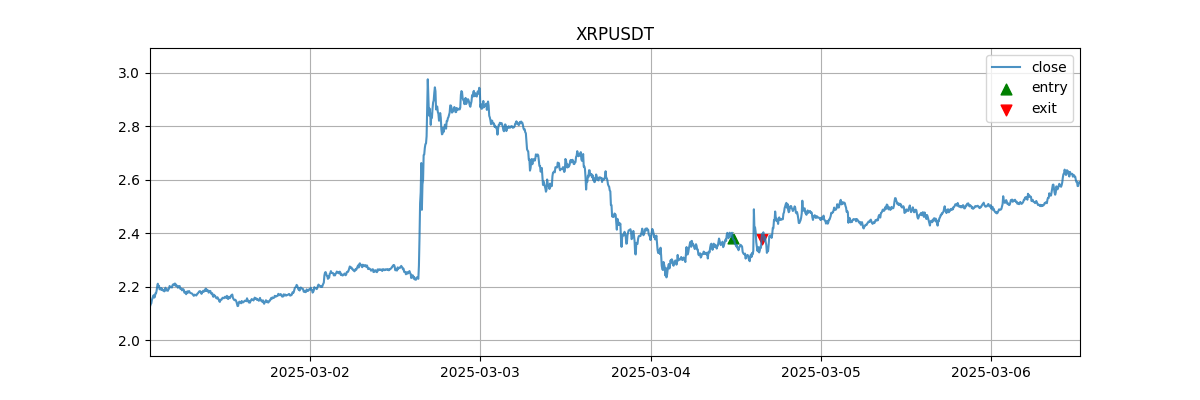

In [128]:
coin_perf["mean_ret"].hist(bins=20)
plt.show()


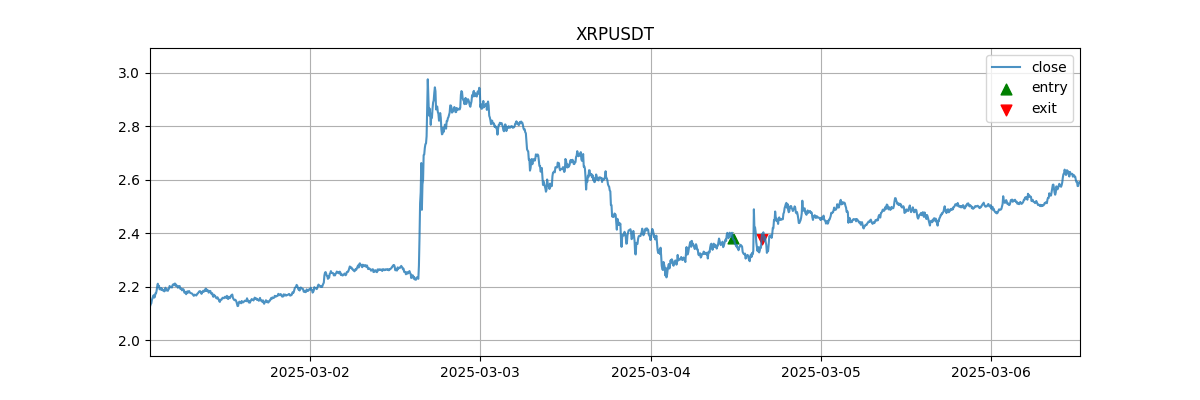

In [127]:
coin_perf["total_ret"].hist(bins=20)
plt.show()

In [121]:
# Best contributor
best = coin_perf.index[0]

# Worst (with n >= 2)
worst = coin_perf.query("n >= 2").sort_values("total_ret").index[0]

# Middle (median total return)
mid = coin_perf.iloc[len(coin_perf)//2].name

best, mid, worst


('PENGUUSDT', 'XRPUSDT', 'VANAUSDT')

In [122]:
import matplotlib.pyplot as plt

def plot_trades_on_price(df, trades, title=""):
    plt.figure(figsize=(12,4))
    plt.plot(df.index, df["close"], label="close", alpha=0.8)

    buys = trades["entry_ts"]
    sells = trades["exit_ts"]

    plt.scatter(buys, df.loc[buys]["close"], marker="^", color="green", s=60, label="entry")
    plt.scatter(sells, df.loc[sells]["close"], marker="v", color="red", s=60, label="exit")

    plt.legend()
    plt.title(title)
    plt.show()


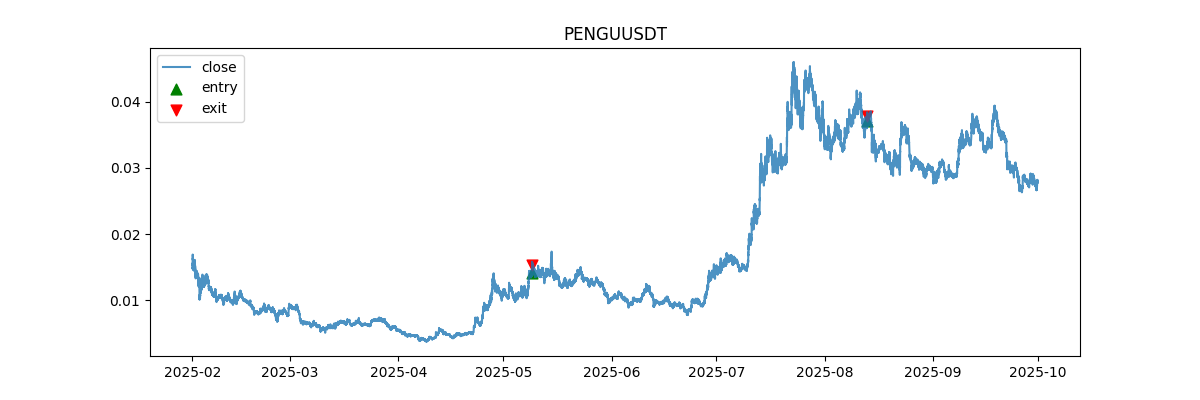

In [124]:
sym = best  # or mid / worst
df = dfs[sym]
t = trades_v5_ref[trades_v5_ref["symbol"] == sym]

plot_trades_on_price(df, t, title=sym)

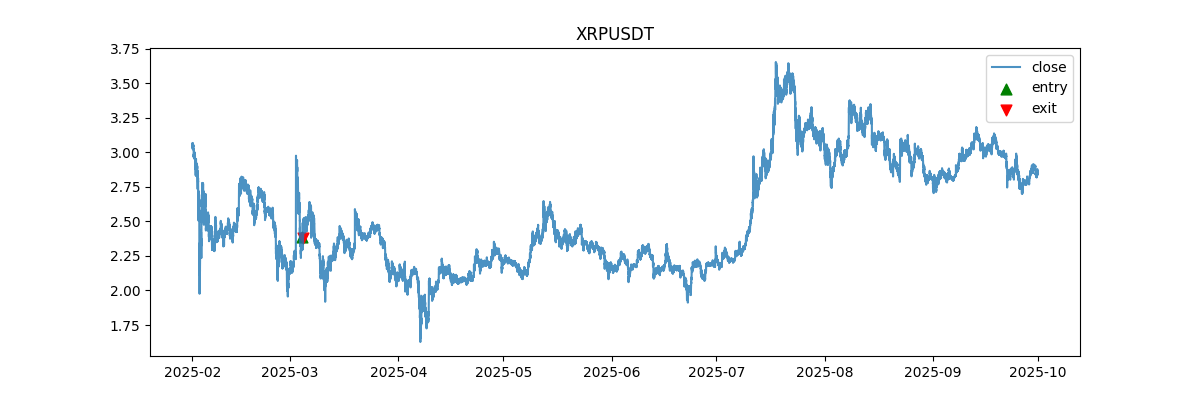

In [125]:
sym = mid  # or mid / worst
df = dfs[sym]
t = trades_v5_ref[trades_v5_ref["symbol"] == sym]

plot_trades_on_price(df, t, title=sym)

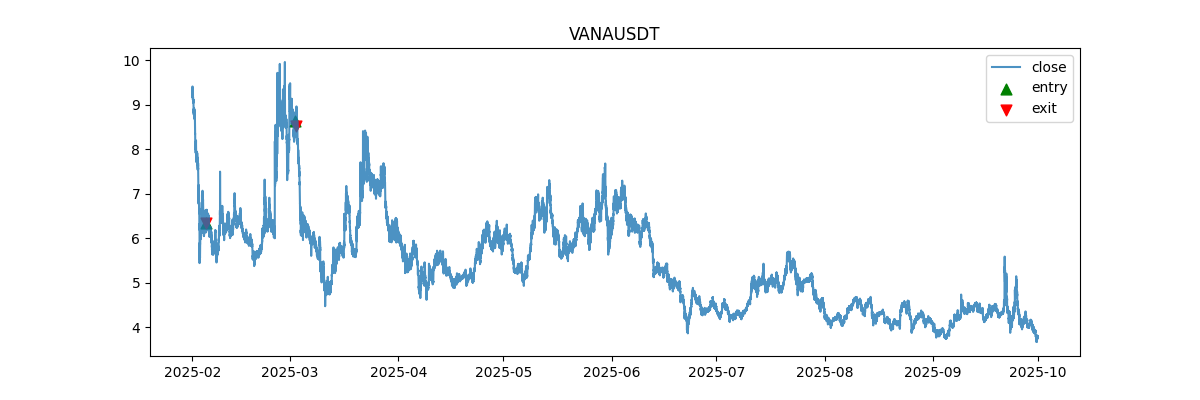

In [129]:
sym = worst  # or mid / worst
df = dfs[sym]
t = trades_v5_ref[trades_v5_ref["symbol"] == sym]

plot_trades_on_price(df, t, title=sym)

In [ ]:
print("cmp rows:", len(cmp))
print("summary overall:")
print(summary["overall"])

print("\nby_bucket:")
print(summary["by_bucket"])

print("\nby_reason:")
print(summary["by_reason"])


In [ ]:
cmp.sort_values("ret_delta", ascending=False)[
    ["symbol","entry_ts","event_ts","comp_bucket_v5","exit_reason","ret_net_base","ret_net_v5","ret_delta"]
].head(10)


# Trading Potfolio

In [ ]:
# 1) Most robust: Q1 only
hf.simulate_portfolio_from_trades(trades_v5_ref, max_open=5, bucket_allow=("Q1 (deep)",))

In [ ]:
# 2) More frequency: Q1 + Q2
hf.simulate_portfolio_from_trades(trades_v5_ref, max_open=5, bucket_allow=("Q1 (deep)","Q2"))

In [ ]:
# 3) Stress: allow all buckets
hf.simulate_portfolio_from_trades(trades_v5_ref, max_open=5, bucket_allow=None)

In [ ]:
res_q1, logs_q1 = hf.simulate_portfolio_v1(
    trades_v5_ref,
    max_open=5,
    cooldown_bars=12,
    bucket_allow=("Q1 (deep)",),
    notional_mode="use_all_cash",
    rank_cols=("compression_score",),
    debug=False,
)
res_q1


In [64]:
logs_q1["skipped"]["reason"].value_counts()

Series([], Name: count, dtype: int64)

In [65]:
MIN_WEEKS = 36

valid_syms = [
    sym for sym, df in dfs.items()
    if (df.index.max() - df.index.min()).total_seconds() >= MIN_WEEKS * 7 * 24 * 3600
]

len(valid_syms), len(dfs)


trades_clean = trades_v5_ref[
    trades_v5_ref["symbol"].isin(valid_syms)
].copy()


In [66]:
res_q1_slip, _ = hf.simulate_portfolio_v1(
    trades_v5_ref,
    max_open=5,
    cooldown_bars=12,
    bucket_allow=("Q1 (deep)",),
    notional_mode="use_all_cash",
    rank_cols=("compression_score",),
    slip_bps=5,
    debug=False,
)
res_q1_slip


{'final_equity': 0.9931230861541269,
 'total_return': -0.006876913845873078,
 'trades_taken': 6,
 'trades_skipped': 0,
 'skip_reasons': Series([], dtype: int64)}

In [ ]:
sweep = hf.run_portfolio_sweep(trades_v5_ref)
sweep.head(20)


## Build Equity Curve

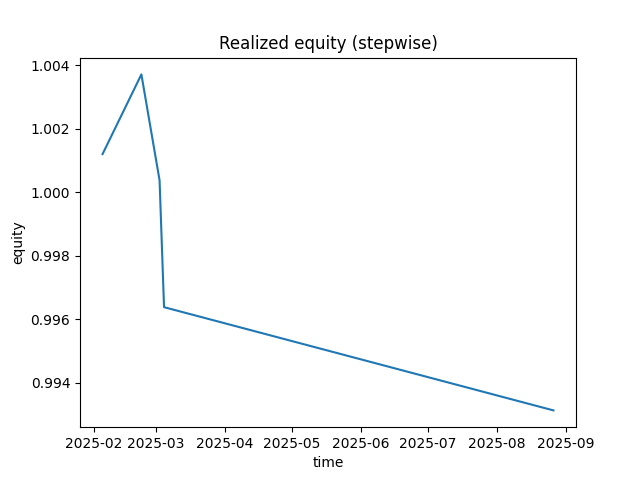

In [68]:
res, logs = hf.simulate_portfolio_v1(
    trades_v5_ref,
    bucket_allow=("Q1 (deep)",),
    max_open=5,
    cooldown_bars=12,
    slip_bps=5,
    notional_mode="use_all_cash",
    rank_cols=("compression_score",),
    debug=False,
)

curve = hf.equity_curve_from_taken(logs["taken"], initial_equity=1.0)

import matplotlib.pyplot as plt
plt.figure()
plt.plot(curve["ts"], curve["equity"])
plt.title("Realized equity (stepwise)")
plt.xlabel("time")
plt.ylabel("equity")
plt.show()


In [86]:
trades_v5_ref.describe()

,entry_ts,event_ts,entry_px,compression_score,exit_ts,exit_px,ret,ret_net,mfe,mae,mfe_A,mae_A,ACTIVATE_ATR,TRAIL_RETRACE,DEAD_BARS,DEAD_MFE_ATR
count,62,62,62.000000,62.000000,62,62.000000,62.000000,62.000000,62.000000,62.000000,62.000000,62.000000,62.000000,62.000000,62.000000,62.000000
mean,2025-07-17 04:22:39.677419776,2025-07-17 07:09:11.612903168,17.300164,-3.962892,2025-07-17 08:38:52.258064640,17.233972,0.018171,0.016171,0.037455,-0.000342,0.016513,0.003971,1.825806,0.370161,26.419355,1.109677
min,2025-02-04 20:10:00,2025-02-04 23:10:00,0.000010,-6.538278,2025-02-04 23:55:00,0.000010,-0.032341,-0.034341,0.000000,-0.032341,-0.032341,-0.032341,1.300000,0.300000,18.000000,0.800000
25%,2025-03-05 08:52:30,2025-03-05 11:50:00,0.204800,-4.844975,2025-03-05 12:05:00,0.208200,-0.013673,-0.015673,0.000678,-0.013673,0.000678,-0.005602,1.300000,0.300000,18.000000,0.800000
50%,2025-08-23 11:15:00,2025-08-23 13:50:00,1.005000,-3.692524,2025-08-23 14:07:30,1.071000,0.002241,0.000241,0.017249,-0.002677,0.012606,0.002885,1.600000,0.350000,24.000000,1.000000
75%,2025-10-12 12:23:45,2025-10-12 14:45:00,3.399250,-3.018760,2025-10-12 20:50:00,3.525250,0.023207,0.021207,0.060227,0.005995,0.026061,0.014165,2.500000,0.450000,36.000000,1.500000
max,2025-12-03 03:40:00,2025-12-03 06:25:00,363.000000,-2.618247,2025-12-03 08:05:00,357.100000,0.132637,0.130637,0.183280,0.076560,0.116743,0.089038,2.500000,0.450000,36.000000,1.500000
std,NaN,NaN,55.442803,1.114204,NaN,54.824776,0.045161,0.045161,0.045747,0.017777,0.024695,0.017950,0.498501,0.062371,7.484516,0.288416


In [69]:
importlib.reload(hf)

<module 'helper_functions' from '/home/ata/binbot/helper_functions.py'>